# Presentación final: análisis de ventas de Amazon

**Propósito:** reunir el contenido y los resultados que puedes convertir después en tus diapositivas. No es una presentación terminada: es el guion analítico, con figuras y métricas reproducibles.

La historia sigue la rúbrica: dataset → insights → problema de predicción → modelos → resultado en test → importancia de variables → conclusión.

## 1. Resumen del dataset

**Mensaje para presentar:** El proyecto analiza un reporte de ventas de Amazon India. Cada fila representa un registro de venta asociado a un producto; el archivo contiene 128,975 filas y 22 columnas. Incluye fecha, estado del pedido, método de gestión, categoría, talla, cantidad, importe y datos de envío. Los importes están denominados en INR.

El periodo observado va de marzo a junio de 2022. El análisis es descriptivo y predictivo sobre estos registros; no permite afirmar que las relaciones observadas sean causales ni que se mantengan en otros periodos.

In [16]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

rutas = [Path('../data/Amazon_Sales.csv'), Path('data/Amazon_Sales.csv')]
ruta = next((p for p in rutas if p.exists()), None)
if ruta is None:
    raise FileNotFoundError('No se encontró data/Amazon_Sales.csv. Ejecuta el notebook desde la carpeta notebooks o desde la raíz del proyecto.')

df = pd.read_csv(ruta)
print(f'Archivo: {ruta.resolve()}')
print(f'Dimensiones: {df.shape[0]:,} filas × {df.shape[1]} columnas')
print(f'Fechas: {df["Date"].min()} a {df["Date"].max()}')
display(df.head(5))

Archivo: /Users/mariajosedelgadofalcon/Desktop/AI_DA_MariaJoseDelgadoFalcon/data/Amazon_Sales.csv
Dimensiones: 128,975 filas × 22 columnas
Fechas: 22/03/31 a 22/06/29


,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,...,Courier Status,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B
0,0,405-8078784-5731545,22/04/30,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,Set,...,Not Shipped,0,INR,647.62,MUMBAI,MAHARASHTRA,400081,IN,No Promotion,False
1,1,171-9198151-1101146,22/04/30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,kurta,...,Shipped,1,INR,406.00,BENGALURU,KARNATAKA,560085,IN,Amazon PLCC Free-Financing Universal Merchant ...,False
2,2,404-0687676-7273146,22/04/30,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,kurta,...,Shipped,1,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True
3,3,403-9615377-8133951,22/04/30,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,Western Dress,...,Not Shipped,0,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008,IN,No Promotion,False
4,4,407-1069790-7240320,22/04/30,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,Top,...,Shipped,1,INR,574.00,CHENNAI,TAMIL NADU,600073,IN,No Promotion,False


## 2. Insights principales del EDA

### Insight 1: la tasa de cancelación difiere descriptivamente por método de gestión
En el análisis existente, los pedidos cancelados representan **12.79%** de los registros gestionados por Amazon y **17.47%** de los gestionados por Merchant. Es una diferencia descriptiva, no evidencia de que el método de gestión cause cancelaciones. Puede mostrarse con el gráfico de estados por método de gestión de `fulfilment_status_analysis.ipynb`.

### Insight 2: el importe se concentra en pocas categorías
Set fue la categoría con mayor importe acumulado (aprox. **39.2 millones INR**), seguida de kurta (aprox. **21.3 millones INR**) y Western Dress (aprox. **11.2 millones INR**). El importe mensual alcanzó su máximo en abril de 2022. El periodo cubre solo cuatro meses, así que no lo describas como una tendencia estacional estable.

### Insight 3: las tallas más vendidas dependen de la categoría
Entre las cinco categorías principales, la talla con mayor proporción fue M para Set (18.45%), L para kurta (17.86%) y Western Dress (18.26%), y XL para Top (17.51%) y Ethnic Dress (16.43%). Las tallas 4XL–6XL tienen muestras mucho menores, por lo que las comparaciones de sus importes son menos precisas.

**Conexión con el modelo:** el primer hallazgo motiva estudiar si datos disponibles del pedido, como gestión, servicio, categoría y talla, ayudan a distinguir registros cancelados. Los otros hallazgos contextualizan el mix de productos y limitan la interpretación.

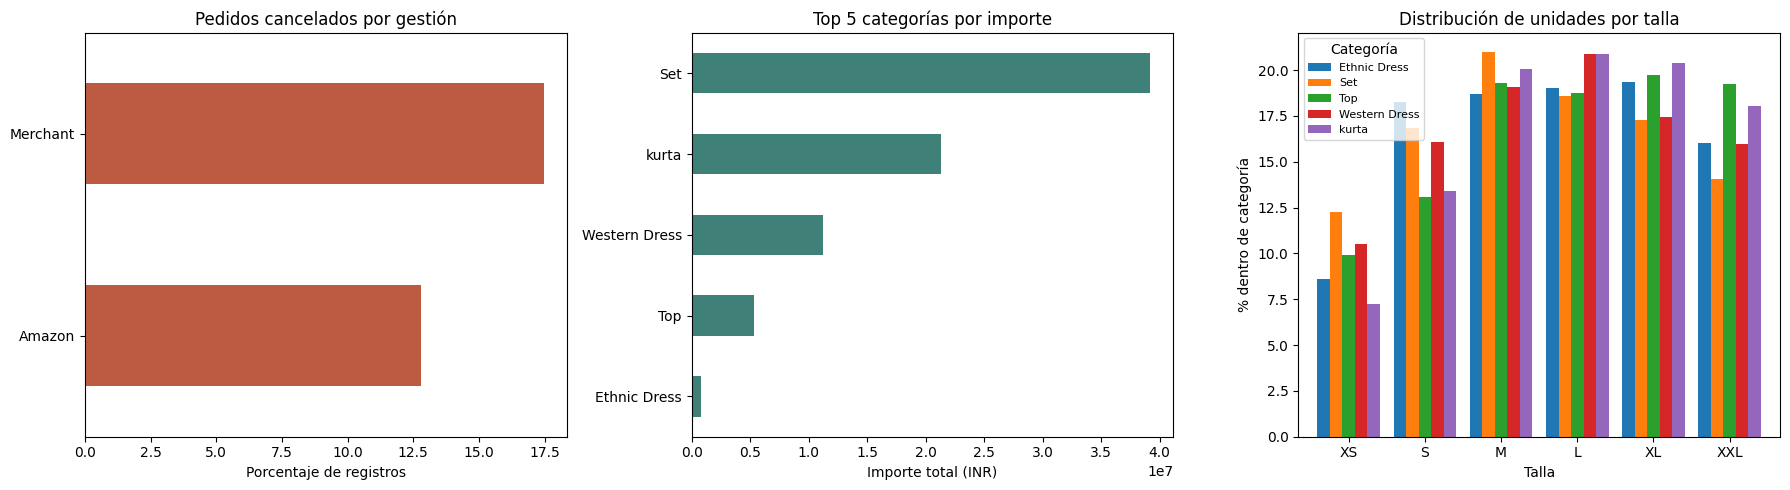

Tasa de cancelación por método de gestión (%):


,Porcentaje
Fulfilment,
Amazon,12.79
Merchant,17.47


Importe total por categoría (INR):


,Amount
Category,
Set,39204124.03
kurta,21299546.70
Western Dress,11216072.69
Top,5347792.30
Ethnic Dress,791217.66


In [2]:
# Visuales compactos para apoyar los hallazgos del EDA.
eda = df.copy()
eda['Amount'] = pd.to_numeric(eda['Amount'], errors='coerce')
eda['Qty'] = pd.to_numeric(eda['Qty'], errors='coerce')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

tasa_cancelacion = (eda.assign(Cancelled=eda['Status'].eq('Cancelled'))
                    .groupby('Fulfilment', dropna=False)['Cancelled'].mean()
                    .mul(100).sort_values())
tasa_cancelacion.plot(kind='barh', ax=axes[0], color='#bd5b42')
axes[0].set_title('Pedidos cancelados por gestión')
axes[0].set_xlabel('Porcentaje de registros')
axes[0].set_ylabel('')

importe_categoria = eda.groupby('Category')['Amount'].sum().sort_values(ascending=False).head(5).sort_values()
importe_categoria.plot(kind='barh', ax=axes[1], color='#3f8178')
axes[1].set_title('Top 5 categorías por importe')
axes[1].set_xlabel('Importe total (INR)')
axes[1].set_ylabel('')

tallas = ['XS', 'S', 'M', 'L', 'XL', 'XXL']
categorias_top = eda.groupby('Category')['Qty'].sum().nlargest(5).index
tabla_tallas = (eda[eda['Category'].isin(categorias_top) & eda['Size'].isin(tallas)]
               .pivot_table(index='Size', columns='Category', values='Qty', aggfunc='sum', fill_value=0))
tabla_pct = tabla_tallas.div(tabla_tallas.sum(axis=0), axis=1).mul(100).reindex(tallas)
tabla_pct.plot(kind='bar', ax=axes[2], width=0.82)
axes[2].set_title('Distribución de unidades por talla')
axes[2].set_xlabel('Talla')
axes[2].set_ylabel('% dentro de categoría')
axes[2].tick_params(axis='x', rotation=0)
axes[2].legend(title='Categoría', fontsize=8)
plt.tight_layout()
plt.show()

print('Tasa de cancelación por método de gestión (%):')
display(tasa_cancelacion.round(2).rename('Porcentaje').to_frame())
print('Importe total por categoría (INR):')
display(eda.groupby('Category')['Amount'].sum().sort_values(ascending=False).head(5).round(2).to_frame())

## 3. Problema de predicción

**Pregunta:** ¿podemos identificar si un registro terminará cancelado usando atributos disponibles del pedido y del producto?

- **Tipo:** clasificación binaria.
- **y:** `1` si `Status == 'Cancelled'`; `0` para los demás estados.
- **X:** método de gestión, canal, nivel de servicio, categoría, talla, estado de envío, indicador B2B, promoción y mes/día de la semana.
- **Unidad de análisis:** registro del archivo. Si un mismo Order ID aparece en varias filas, todas sus filas se mantienen en el mismo split.
- **Cuidado con leakage:** se excluyen `Status`, `Courier Status`, `Qty` y `Amount`, porque describen o pueden reflejar el resultado posterior del pedido. También se excluyen identificadores como Order ID, SKU y ASIN.

Como Cancelled es una clase minoritaria, además de accuracy se reportan precision, recall y F1 para la clase cancelada. La selección de modelo se hará por F1 de validación para no premiar simplemente la predicción de la clase mayoritaria.

In [17]:
from sklearn.model_selection import GroupShuffleSplit

datos = df.loc[df['Status'].notna()].copy()
datos['Date_parsed'] = pd.to_datetime(datos['Date'], format='%y/%m/%d', errors='coerce')
datos['Date_month'] = datos['Date_parsed'].dt.month
datos['Date_weekday'] = datos['Date_parsed'].dt.dayofweek
datos['Cancelled'] = datos['Status'].eq('Cancelled').astype('int8')

columnas_categoricas = [
    'Fulfilment', 'Sales Channel', 'ship-service-level', 'Category',
    'Size', 'ship-state', 'B2B', 'promotion-ids'
]
columnas_numericas = ['Date_month', 'Date_weekday']
columnas_x = columnas_categoricas + columnas_numericas
X = datos[columnas_x].copy()
y = datos['Cancelled'].copy()

# Evitar que filas del mismo pedido aparezcan en más de una partición.
grupos = datos['Order ID'].astype('string')
grupos = grupos.fillna(pd.Series([f'__missing_{i}' for i in datos.index], index=datos.index))
split_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=42)
idx_trainval, idx_test = next(split_test.split(X, y, groups=grupos))
X_trainval, X_test = X.iloc[idx_trainval], X.iloc[idx_test]
y_trainval, y_test = y.iloc[idx_trainval], y.iloc[idx_test]
groups_trainval = grupos.iloc[idx_trainval]
split_val = GroupShuffleSplit(n_splits=1, test_size=0.1765, random_state=43)
idx_train_rel, idx_val_rel = next(split_val.split(X_trainval, y_trainval, groups=groups_trainval))
X_train, X_val = X_trainval.iloc[idx_train_rel], X_trainval.iloc[idx_val_rel]
y_train, y_val = y_trainval.iloc[idx_train_rel], y_trainval.iloc[idx_val_rel]

assert set(groups_trainval.iloc[idx_train_rel]).isdisjoint(set(groups_trainval.iloc[idx_val_rel]))
assert set(groups_trainval).isdisjoint(set(grupos.iloc[idx_test]))
print(f'Registros utilizables: {len(datos):,}')
print(f'Train: {len(X_train):,} | Validación: {len(X_val):,} | Test: {len(X_test):,}')
print(f'Proporción Cancelled total: {y.mean():.2%}')
display(pd.DataFrame({
    'Registros': [len(y_train), len(y_val), len(y_test)],
    'Proporción Cancelled': [y_train.mean(), y_val.mean(), y_test.mean()]
}, index=['Train', 'Validación', 'Test']).round(4))

Registros utilizables: 128,975
Train: 90,306 | Validación: 19,300 | Test: 19,369
Proporción Cancelled total: 14.21%


,Registros,Proporción Cancelled
Train,90306,0.1423
Validación,19300,0.1406
Test,19369,0.1429


## 4. Modelos y evaluación

Se comparan un baseline de clase más frecuente, una regresión logística y un árbol de decisión acotado. El preprocesamiento se ajusta dentro de cada pipeline usando solo train: imputación de faltantes y one-hot encoding para las variables categóricas. El test queda reservado hasta elegir el modelo por F1 de validación.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

preprocesamiento = ColumnTransformer(transformers=[
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=100))
    ]), columnas_categoricas),
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), columnas_numericas)
])

modelos = {
    'Regresión logística': Pipeline([
        ('preprocess', preprocesamiento),
        ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
    ]),
    'Árbol de decisión (profundidad 8)': Pipeline([
        ('preprocess', preprocesamiento),
        ('model', DecisionTreeClassifier(max_depth=8, min_samples_leaf=100, class_weight='balanced', random_state=42))
    ])
}
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)

def metricas(y_real, y_pred):
    return {
        'Accuracy': accuracy_score(y_real, y_pred),
        'Precision Cancelled': precision_score(y_real, y_pred, zero_division=0),
        'Recall Cancelled': recall_score(y_real, y_pred, zero_division=0),
        'F1 Cancelled': f1_score(y_real, y_pred, zero_division=0)
    }

filas = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)
    filas.append({'Modelo': nombre, 'Partición': 'Train (umbral 0.5)', **metricas(y_train, pred_train)})
    filas.append({'Modelo': nombre, 'Partición': 'Validación (umbral 0.5)', **metricas(y_val, pred_val)})

filas.append({'Modelo': 'Baseline (clase más frecuente)', 'Partición': 'Train', **metricas(y_train, baseline.predict(X_train))})
filas.append({'Modelo': 'Baseline (clase más frecuente)', 'Partición': 'Validación', **metricas(y_val, baseline.predict(X_val))})
tabla_umbral_base = pd.DataFrame(filas).set_index(['Modelo', 'Partición']).sort_index()
print('Comparación inicial con umbral por defecto (0.5):')
display(tabla_umbral_base.round(3))
print('Ambos modelos usan class_weight=balanced. La siguiente sección ajusta el umbral con validación.')

Comparación inicial con umbral por defecto (0.5):


Accuracy  \
Modelo                            Partición                           
Baseline (clase más frecuente)    Train                       0.858   
                                  Validación                  0.859   
Regresión logística               Train (umbral 0.5)          0.768   
                                  Validación (umbral 0.5)     0.771   
Árbol de decisión (profundidad 8) Train (umbral 0.5)          0.769   
                                  Validación (umbral 0.5)     0.771   

                                                           Precision Cancelled  \
Modelo                            Partición                                      
Baseline (clase más frecuente)    Train                                  0.000   
                                  Validación                             0.000   
Regresión logística               Train (umbral 0.5)                     0.378   
                                  Validación (umbral 0.5)                0.378   
Árbol de decisión (profundidad 8) Train (umbral 0.5)                     0.379   
                                  Validación (umbral 0.5)                0.378   

                                                           Recall Cancelled  \
Modelo                            Partición                                   
Baseline (clase más frecuente)    Train                               0.000   
                                  Validación                          0.000   
Regresión logística               Train (umbral 0.5)                  0.975   
                                  Validación (umbral 0.5)             0.973   
Árbol de decisión (profundidad 8) Train (umbral 0.5)                  0.975   
                                  Validación (umbral 0.5)             0.973   

                                                           F1 Cancelled  
Modelo                            Partición                              
Baseline (clase más frecuente)    Train                           0.000  
                                  Validación                      0.000  
Regresión logística               Train (umbral 0.5)              0.545  
                                  Validación (umbral 0.5)         0.544  
Árbol de decisión (profundidad 8) Train (umbral 0.5)              0.546  
                                  Validación (umbral 0.5)         0.545

Ambos modelos usan class_weight=balanced. La siguiente sección ajusta el umbral con validación.


### Cómo manejar el desbalance y elegir el umbral

Los modelos ya usan `class_weight='balanced'`, así que el desbalance sí se considera en el entrenamiento. El umbral predeterminado de 0.5 puede, aun así, favorecer demasiadas predicciones de cancelación. La celda siguiente compara ese punto de corte con uno elegido para maximizar F1 **solo en validación**. El umbral es una decisión de operación: maximizar F1 equilibra precision y recall, pero una empresa podría preferir otro balance según el coste de cada error. El baseline sirve como referencia y no debe evaluarse en test.

In [13]:
from sklearn.metrics import precision_recall_curve

umbrales_modelo = {}
predicciones_train_ajustadas = {}
predicciones_validacion = {}
filas_umbral = []
filas_metricas_ajustadas = []

for nombre, modelo in modelos.items():
    prob_val = modelo.predict_proba(X_val)[:, 1]
    precision_curva, recall_curva, umbrales = precision_recall_curve(y_val, prob_val)
    f1_curva = (2 * precision_curva[:-1] * recall_curva[:-1] /
                (precision_curva[:-1] + recall_curva[:-1] + 1e-12))
    indice_mejor = int(np.argmax(f1_curva))
    umbral = float(umbrales[indice_mejor])
    umbrales_modelo[nombre] = umbral

    pred_val_defecto = modelo.predict(X_val)
    pred_val_ajustada = (prob_val >= umbral).astype('int8')
    prob_train = modelo.predict_proba(X_train)[:, 1]
    pred_train_ajustada = (prob_train >= umbral).astype('int8')
    predicciones_train_ajustadas[nombre] = pred_train_ajustada
    predicciones_validacion[nombre] = pred_val_ajustada

    filas_umbral.append({
        'Modelo': nombre, 'Punto de corte': 'Por defecto (0.5)', 'Umbral': 0.5,
        **metricas(y_val, pred_val_defecto)
    })
    filas_umbral.append({
        'Modelo': nombre, 'Punto de corte': 'F1 máximo en validación', 'Umbral': umbral,
        **metricas(y_val, pred_val_ajustada)
    })
    filas_metricas_ajustadas.append({
        'Modelo': nombre, 'Partición': 'Train', **metricas(y_train, pred_train_ajustada)
    })
    filas_metricas_ajustadas.append({
        'Modelo': nombre, 'Partición': 'Validación', **metricas(y_val, pred_val_ajustada)
    })

filas_metricas_ajustadas.extend([
    {'Modelo': 'Baseline (clase más frecuente)', 'Partición': 'Train',
     **metricas(y_train, baseline.predict(X_train))},
    {'Modelo': 'Baseline (clase más frecuente)', 'Partición': 'Validación',
     **metricas(y_val, baseline.predict(X_val))}
])
tabla_metricas = pd.DataFrame(filas_metricas_ajustadas).set_index(['Modelo', 'Partición']).sort_index()

print('Comparación del punto de corte en validación:')
display(pd.DataFrame(filas_umbral).set_index(['Modelo', 'Punto de corte']).round(3))
print('\nMétricas con el umbral elegido para cada modelo:')
display(tabla_metricas.round(3))

mejor_nombre = max(
    modelos,
    key=lambda nombre: tabla_metricas.loc[(nombre, 'Validación'), 'F1 Cancelled']
)
mejor_umbral = umbrales_modelo[mejor_nombre]
mejor_validacion_f1 = tabla_metricas.loc[(mejor_nombre, 'Validación'), 'F1 Cancelled']
print(
    f'Modelo elegido por F1 de validación: {mejor_nombre}; '
    f'umbral={mejor_umbral:.4f}; F1={mejor_validacion_f1:.3f}'
)
print('Si el umbral elegido no mejora precision y F1 frente a 0.5, no hay una mejora real: revisa la tabla y el objetivo operativo.')

Comparación del punto de corte en validación:


Umbral  Accuracy  \
Modelo                            Punto de corte                              
Regresión logística               Por defecto (0.5)         0.500     0.771   
                                  F1 máximo en validación   0.766     0.907   
Árbol de decisión (profundidad 8) Por defecto (0.5)         0.500     0.771   
                                  F1 máximo en validación   0.764     0.903   

                                                           Precision Cancelled  \
Modelo                            Punto de corte                                 
Regresión logística               Por defecto (0.5)                      0.378   
                                  F1 máximo en validación                0.719   
Árbol de decisión (profundidad 8) Por defecto (0.5)                      0.378   
                                  F1 máximo en validación                0.679   

                                                           Recall Cancelled  \
Modelo                            Punto de corte                              
Regresión logística               Por defecto (0.5)                   0.973   
                                  F1 máximo en validación             0.554   
Árbol de decisión (profundidad 8) Por defecto (0.5)                   0.973   
                                  F1 máximo en validación             0.587   

                                                           F1 Cancelled  
Modelo                            Punto de corte                         
Regresión logística               Por defecto (0.5)               0.544  
                                  F1 máximo en validación         0.626  
Árbol de decisión (profundidad 8) Por defecto (0.5)               0.545  
                                  F1 máximo en validación         0.630


Métricas con el umbral elegido para cada modelo:


Accuracy  Precision Cancelled  \
Modelo                            Partición                                   
Baseline (clase más frecuente)    Train          0.858                0.000   
                                  Validación     0.859                0.000   
Regresión logística               Train          0.906                0.723   
                                  Validación     0.907                0.719   
Árbol de decisión (profundidad 8) Train          0.898                0.662   
                                  Validación     0.903                0.679   

                                              Recall Cancelled  F1 Cancelled  
Modelo                            Partición                                   
Baseline (clase más frecuente)    Train                  0.000         0.000  
                                  Validación             0.000         0.000  
Regresión logística               Train                  0.546         0.622  
                                  Validación             0.554         0.626  
Árbol de decisión (profundidad 8) Train                  0.582         0.619  
                                  Validación             0.587         0.630

Modelo elegido por F1 de validación: Árbol de decisión (profundidad 8); umbral=0.7639; F1=0.630
Si el umbral elegido no mejora precision y F1 frente a 0.5, no hay una mejora real: revisa la tabla y el objetivo operativo.


## 5. Resultado final en test

Se conserva el modelo entrenado con train y el umbral elegido con validación para que el punto de corte siga correspondiendo a sus probabilidades. El modelo seleccionado se evalúa una sola vez en test; no se usa test para ajustar el umbral.

In [14]:
mejor_modelo = modelos[mejor_nombre]
prob_test = mejor_modelo.predict_proba(X_test)[:, 1]
pred_test = (prob_test >= mejor_umbral).astype('int8')
metricas_test = metricas(y_test, pred_test)

filas_resumen = []
for nombre in ['Baseline (clase más frecuente)', *modelos.keys()]:
    fila = {'Modelo': nombre}
    for particion in ['Train', 'Validación']:
        valores = tabla_metricas.loc[(nombre, particion)]
        fila[f'{particion} accuracy'] = f'{valores["Accuracy"]:.3f}'
        fila[f'{particion} F1'] = f'{valores["F1 Cancelled"]:.3f}'
    fila['Umbral aplicado'] = f'{umbrales_modelo[nombre]:.4f}' if nombre in umbrales_modelo else 'No aplica'
    fila['Test accuracy'] = f'{metricas_test["Accuracy"]:.3f}' if nombre == mejor_nombre else 'No aplica'
    fila['Test F1'] = f'{metricas_test["F1 Cancelled"]:.3f}' if nombre == mejor_nombre else 'No aplica'
    filas_resumen.append(fila)

print('Tabla resumida para la presentación (test solo para el modelo elegido):')
display(pd.DataFrame(filas_resumen).set_index('Modelo'))
display(pd.DataFrame([metricas_test], index=[mejor_nombre]).round(3))

print(
    f'En el conjunto de prueba, el modelo detectó {metricas_test["Recall Cancelled"]:.1%} '
    f'de los registros cancelados (recall). De los registros que marcó como cancelados, '
    f'{metricas_test["Precision Cancelled"]:.1%} realmente lo estaban (precision). '
    f'El F1 fue {metricas_test["F1 Cancelled"]:.3f} y la accuracy global {metricas_test["Accuracy"]:.1%}. '
    'El recall y la precision muestran el compromiso real del umbral elegido. Estos resultados describen este test '
    'y no garantizan el mismo desempeño en datos futuros.'
)

Tabla resumida para la presentación (test solo para el modelo elegido):


,Train accuracy,Train F1,Validación accuracy,Validación F1,Umbral aplicado,Test accuracy,Test F1
Modelo,,,,,,,
Baseline (clase más frecuente),0.858,0.000,0.859,0.000,No aplica,No aplica,No aplica
Regresión logística,0.906,0.622,0.907,0.626,0.7665,No aplica,No aplica
Árbol de decisión (profundidad 8),0.898,0.619,0.903,0.630,0.7639,0.904,0.639


,Accuracy,Precision Cancelled,Recall Cancelled,F1 Cancelled
Árbol de decisión (profundidad 8),0.904,0.691,0.593,0.639


En el conjunto de prueba, el modelo detectó 59.3% de los registros cancelados (recall). De los registros que marcó como cancelados, 69.1% realmente lo estaban (precision). El F1 fue 0.639 y la accuracy global 90.4%. El recall y la precision muestran el compromiso real del umbral elegido. Estos resultados describen este test y no garantizan el mismo desempeño en datos futuros.


## 6. Variables más importantes

El gráfico agrupa las importancias por variable original, sumando las columnas creadas por one-hot encoding. Si gana el árbol se muestran importancias del árbol; si gana la regresión logística se muestran coeficientes absolutos. Son medidas asociativas del modelo, no efectos causales. Compara los primeros lugares con el insight de gestión y con los patrones de categoría del EDA.

,Importancia
Variable,
promotion-ids,0.8797
Fulfilment,0.0855
ship-state,0.0143
Category,0.0086
ship-service-level,0.0084
Size,0.0020
Date,0.0014
B2B,0.0000
Sales Channel,0.0000


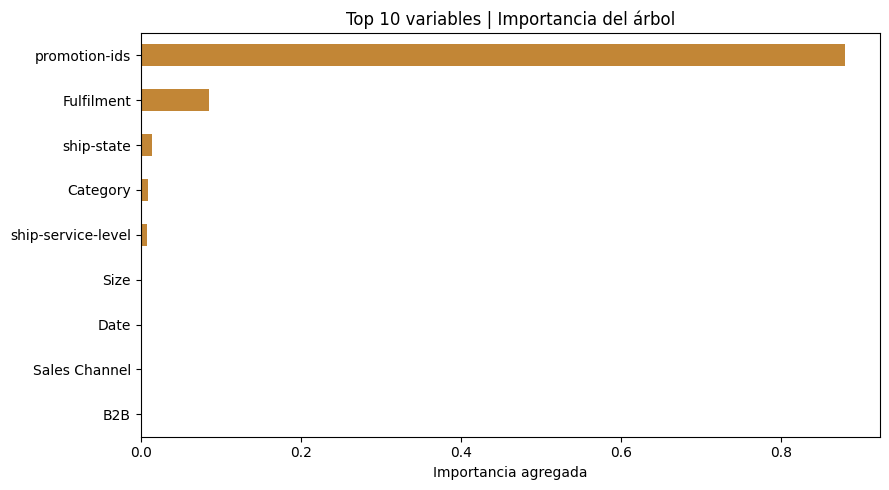

Lectura del resultado observado: promotion-ids concentra cerca del 88% de la importancia y Fulfilment cerca del 9%. Fulfilment coincide con el patrón descriptivo del EDA. Antes de defender el peso de promotion-ids, verifica que su valor esté disponible al momento de predecir y que no codifique información posterior al resultado. La importancia es asociativa, no causal.


In [15]:
modelo_entrenado = mejor_modelo.named_steps['model']
nombres_transformados = mejor_modelo.named_steps['preprocess'].get_feature_names_out()
if hasattr(modelo_entrenado, 'feature_importances_'):
    valores_importancia = modelo_entrenado.feature_importances_
    tipo_importancia = 'Importancia del árbol'
else:
    valores_importancia = np.abs(modelo_entrenado.coef_[0])
    tipo_importancia = 'Coeficiente absoluto (regresión logística)'

importancias = pd.DataFrame({'Feature': nombres_transformados, 'Importancia': valores_importancia})
importancias['Variable'] = importancias['Feature'].str.replace(r'^(cat|num)__', '', regex=True).str.split('_').str[0]
importancia_variable = importancias.groupby('Variable')['Importancia'].sum().sort_values(ascending=False)
display(importancia_variable.head(10).to_frame().round(4))
ax = importancia_variable.head(10).sort_values().plot(kind='barh', figsize=(9, 5), color='#c28636')
ax.set_title(f'Top 10 variables | {tipo_importancia}')
ax.set_xlabel('Importancia agregada')
ax.set_ylabel('')
plt.tight_layout()
plt.show()
print(
    'Lectura del resultado observado: promotion-ids concentra cerca del 88% de la importancia y Fulfilment cerca del 9%. '
    'Fulfilment coincide con el patrón descriptivo del EDA. Antes de defender el peso de promotion-ids, verifica que '
    'su valor esté disponible al momento de predecir y que no codifique información posterior al resultado. '
    'La importancia es asociativa, no causal.'
)

## 7. Conclusión y siguientes pasos

**Resultado:** los modelos ya compensan la clase minoritaria con `class_weight='balanced'`; además, se eligió el umbral usando F1 de validación. El árbol de decisión obtuvo el mayor F1 de validación (0.630 con umbral 0.7639), frente a 0.626 para la regresión logística. Train y validación tienen métricas cercanas, sin una señal clara de overfitting. En el test reservado, el árbol obtuvo 90.4% de accuracy, 69.1% de precision, 59.3% de recall y F1=0.639 para cancelaciones. En palabras sencillas: de cada 100 registros que marca como cancelados, alrededor de 69 sí lo están; detecta alrededor de 59 de cada 100 cancelaciones reales.

El baseline alcanza 85.9% de accuracy en validación por predecir siempre la clase mayoritaria, pero no identifica cancelaciones (F1=0). El árbol con umbral elegido mejora F1 de validación frente al umbral 0.5 (0.630 frente a 0.545) y conserva un balance más útil entre precision y recall. Esta comparación favorece F1 porque interesa encontrar cancelaciones sin generar tantas falsas alarmas; si el coste operativo cambia, también debería cambiar el criterio de selección del umbral.

**Conclusión para presentar:** el modelo puede ayudar a priorizar pedidos para revisión, pero no debería cancelar pedidos automáticamente. Sus métricas son un compromiso entre encontrar cancelaciones y reducir falsas alarmas; el umbral debe responder al coste real de esos errores.

**Limitaciones:** el archivo cubre marzo–junio de 2022; el split aleatorio por Order ID evita que un pedido se repita entre particiones, pero no simula por completo el futuro. Para una aplicación real convendría validar con una separación temporal, probar datos más recientes, revisar el coste de falsos positivos/falsos negativos y verificar la disponibilidad de cada variable al momento de predecir. `promotion-ids` concentra casi 88% de la importancia y merece una auditoría de disponibilidad temporal. Los resultados son asociaciones, no causalidad.

**Respuesta breve a “¿qué harías diferente?”:** añadiría más meses de datos y una validación temporal; después ajustaría el umbral según el coste de cada tipo de error.

## Orden sugerido para tus diapositivas

1. Título y pregunta del proyecto.
2. Dataset: origen, periodo, filas y qué representa cada fila.
3. Dos o tres insights del EDA, con 1–2 gráficos legibles.
4. Problema: qué es y, qué es X, por qué clasificación y cómo evitaste leakage.
5. Tabla de baseline y modelos: train y validación; elección por F1 de validación; comentario de overfitting.
6. Test del modelo elegido: métrica en lenguaje cotidiano.
7. Importancia de variables y comparación con el EDA.
8. Conclusión, limitaciones y siguiente paso.

Para una presentación individual de 5–8 minutos, dedica la mayor parte del tiempo a la pregunta, los resultados y su interpretación. Deja listas respuestas a: “¿por qué este y?”, “¿por qué este modelo?”, “¿qué significa el recall/F1?” y “¿qué variables podrían causar leakage?”.

## Checklist antes de presentar

- Ejecutar este notebook de arriba abajo y confirmar que las métricas y figuras se generan sin error.
- Copiar a las diapositivas únicamente resultados generados por esta versión del notebook.
- Dejar en el repositorio el notebook de EDA, este notebook final, el README actualizado, el dataset o instrucciones para obtenerlo, y el PDF/enlace de las diapositivas.
- En el README incluir descripción del dataset, y, X, tipo de problema, tabla de resultados y conclusión.
- Subir los cambios a GitHub antes de presentar.